# Museum guide: a walkthrough of the results

A mid-sized French fine-arts museum wants a guide for visitors' phones and gallery kiosks: **recognise** the painting a visitor points the camera at
(its genre or style, and the story of that tradition), and **answer questions** in natural language. The director also asks whether a neural network is worth it
in production, or whether a simpler classical model would do.

This notebook is a reader's guide to the answer. It does **not** retrain anything: every number and chart is computed from the result files committed in
`reports/` (no data, no model, no network needed, it runs in a few seconds). The scripts that produced each file are named in the README.
No painting is shown here on purpose: the paintings come from WikiArt and must not be published.

In [ ]:
import json
import pathlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# The repository root: the closest parent folder that has a reports/ directory.
ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "reports").is_dir())


def R(name):
    """Load reports/<name>.json."""
    return json.loads((ROOT / "reports" / f"{name}.json").read_text())


COLORS = {"classical": "#8a8a8a", "mlp": "#d9822b", "resnet": "#2f6db5", "clip": "#2a9d6e", "floor": "#c9c9c9"}
plt.rcParams.update({
    "figure.dpi": 80, "savefig.dpi": 80, "font.size": 9, "axes.grid": True, "grid.alpha": 0.3, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
})


def pct(x, digits=1):
    """Percentage, rounded half up (like the README), e.g. 0.0325 -> 3.3%."""
    return f"{100 * x + 1e-9:.{digits}f}%"


def mean_std(d):
    return f"{100 * d['mean']:.1f}% ± {100 * d['std']:.1f}"


print("Reports found:", len(list((ROOT / "reports").glob("*.json"))))

Reports found: 22


## 1. The data, and why the split is by artist

The task uses a subset of WikiArt: five genres (cityscape, landscape, portrait, religious painting, still life), a few hundred paintings each.
A painter's hand (palette, brushwork, framing) is easy to memorise, so if the same artist is in train and test, accuracy measures recognition of the *artist*.
The museum will show paintings by artists the model never saw, so the split is **grouped by artist**. Caveat: a large share of the images (printed below) are "Unknown Artist" and each
of them is its own group, so the guarantee only covers *named* painters.

Before trusting any model, the data audit asks how well a model that **never sees the painting** can do, using only metadata. Those "floors" are the bar a real model must clear.

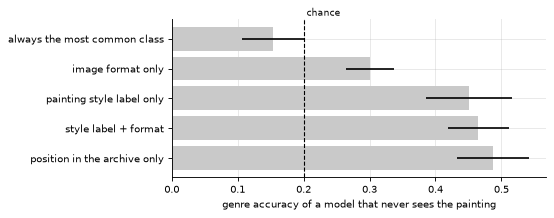

Unknown-artist share in the split of seed 0: train 52% (972 images), val 44% (249 images), test 37% (279 images)
Near-duplicate paintings found by a perceptual hash (up to 3 differing bits out of 64): 0 pairs in 1500 images.


In [ ]:
audit = R("data_audit")
floors = audit["metadata_floors"]
n_classes = len(audit["split_composition"]["seed0"]["train"]["class_share"])
labels = {
    "majority_class": "always the most common class",
    "format": "image format only",
    "style": "painting style label only",
    "style+format": "style label + format",
    "shard_majority": "position in the archive only",
}
order = ["majority_class", "format", "style", "style+format", "shard_majority"]

fig, ax = plt.subplots(figsize=(7, 2.8))
ax.barh([labels[k] for k in order], [floors[k]["mean"] for k in order], xerr=[floors[k]["std"] for k in order], color=COLORS["floor"])
ax.axvline(1 / n_classes, color="black", ls="--", lw=1)
ax.text(1 / n_classes, 1.01, " chance", transform=ax.get_xaxis_transform(), va="bottom", fontsize=8)
ax.set_xlabel("genre accuracy of a model that never sees the painting")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

comp = audit["split_composition"]["seed0"]
print("Unknown-artist share in the split of seed 0: " + ", ".join(f"{part} {pct(comp[part]['unknown_artist_share'], 0)} ({comp[part]['n']} images)" for part in ("train", "val", "test")))
print(f"Near-duplicate paintings found by a perceptual hash (up to 3 differing bits out of 64): {audit['near_duplicates']['dhash8']['max_distance_3']['pairs']} pairs in {audit['n_images']} images.")

## 2. The simple answer: a classical model

The director's question is whether a simpler model does the job. The classical baseline summarises each image with hand-made colour and edge features
and fits logistic regression or a random forest. It is cheap, and it is the yardstick for everything that follows.

In [ ]:
base = R("baseline_classical")
table = pd.DataFrame({"Logistic regression": base["logistic_regression"], "Random forest": base["random_forest"]}).T
table = table[["val_acc", "test_acc", "test_macro_f1", "cpu_latency_ms"]]
table.columns = ["validation accuracy", "test accuracy", "test macro-F1", "CPU latency (ms)"]
print(f"{base['n_features']} colour and edge features per image; single split (seed 0).")
table.round(3)

126 colour and edge features per image; single split (seed 0).


,validation accuracy,test accuracy,test macro-F1,CPU latency (ms)
Logistic regression,0.450,0.502,0.491,1.534
Random forest,0.474,0.538,0.529,11.964


## 3. A feed-forward network, and what went wrong with it

A network written from PyTorch primitives, trained on pixels. The monitoring follows the usual checks: it can memorise a tiny set (so the code works), the learning rate
matters (too high and the loss explodes), and without regularisation it overfits (training accuracy climbs while validation stalls).
The failure diagnosis is the last chart: an MLP ties each weight to one pixel position, so shifting the image should hurt it.

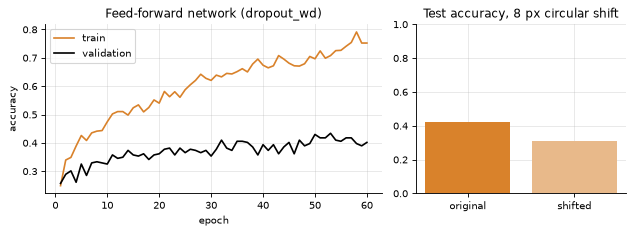

Sanity check: it memorises 64 images (100% train accuracy), so the code and gradients work.
A circular shift of the test images changes 63% of its predictions; test accuracy 41.9% -> 30.8%.


In [ ]:
mlp = R("mlp")
hist, fin = mlp["history"], mlp["final"]
fig, (a, b) = plt.subplots(1, 2, figsize=(8, 3), gridspec_kw={"width_ratios": [1.6, 1]})
epochs = np.arange(1, len(hist["train_acc"]) + 1)
a.plot(epochs, hist["train_acc"], color=COLORS["mlp"], label="train")
a.plot(epochs, hist["val_acc"], color="black", label="validation")
a.set_xlabel("epoch")
a.set_ylabel("accuracy")
a.set_title(f"Feed-forward network ({fin['config']})")
a.legend()
b.bar(["original", "shifted"], [fin["test_acc"], fin["test_acc_shifted_8px"]], color=[COLORS["mlp"], "#e8b98a"])
b.set_ylim(0, 1)
b.set_title("Test accuracy, 8 px circular shift")
plt.tight_layout()
plt.show()

sanity = mlp["sanity_overfit_64_images"]
print(f"Sanity check: it memorises 64 images ({pct(sanity['final_train_acc'], 0)} train accuracy), so the code and gradients work.")
print(f"A circular shift of the test images changes {pct(fin['prediction_change_rate_shifted'], 0)} of its predictions; test accuracy {pct(fin['test_acc'])} -> {pct(fin['test_acc_shifted_8px'])}.")

## 4. A pretrained network

Trained from scratch on a few hundred images, a ResNet-18 overfits. With ImageNet weights, training only the new head already works much better, and also fine-tuning the last block
works a little better still. The jump comes from **pretraining**, not from the architecture.

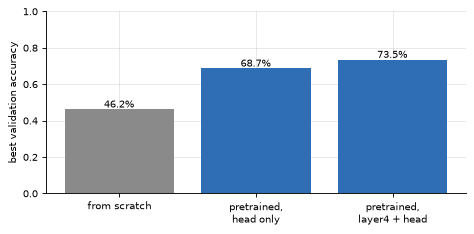

Trainable parameters: from scratch 11,179,077, pretrained, head only 2,565, pretrained, layer4 + head 8,396,293
Selected variant (pretrained_layer4): test accuracy 74.6% on the seed-0 split.


In [ ]:
res = R("resnet")
names = {"scratch": "from scratch", "pretrained_head_only": "pretrained,\nhead only", "pretrained_layer4": "pretrained,\nlayer4 + head"}
vals = [res[k]["best_val_acc"] for k in names]
fig, ax = plt.subplots(figsize=(6, 3))
bars = ax.bar(list(names.values()), vals, color=[COLORS["classical"], COLORS["resnet"], COLORS["resnet"]])
for rect, v in zip(bars, vals):
    ax.text(rect.get_x() + rect.get_width() / 2, v + 0.01, pct(v), ha="center")
ax.set_ylim(0, 1)
ax.set_ylabel("best validation accuracy")
plt.tight_layout()
plt.show()
print("Trainable parameters: " + ", ".join(f"{label.replace(chr(10), ' ')} {res[k]['trainable_params']:,}" for k, label in names.items()))
print(f"Selected variant ({res['final']['variant']}): test accuracy {pct(res['final']['test_acc'])} on the seed-0 split.")

## 5. How solid are these numbers?

One split and one training run on a small test set is a weak basis for a recommendation. The comparison is therefore repeated over several seeds (a seed changes the artist-disjoint
split **and** the training randomness), and the intervals resample *artists*, not single images, because paintings by one painter are not independent.

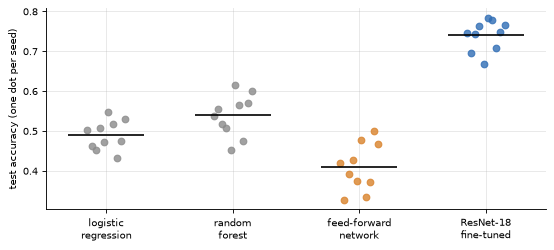

10 seeds. Mean ± std: logistic regression 49.0% ± 3.7; random forest 53.9% ± 5.2; feed-forward network 40.9% ± 6.0; ResNet-18 fine-tuned 74.0% ± 3.8
Seed 0, ResNet minus random forest: +20.8 points, 95% interval [+14.5, +26.9].
Seed 0, random forest minus logistic regression: +3.6 points, 95% interval [-2.1, +9.9].
Seeds where the ResNet beats the random forest: 10 of 10


In [ ]:
rob = R("robustness")
models = [("logistic_regression", "logistic\nregression", "classical"), ("random_forest", "random\nforest", "classical"),
          ("mlp", "feed-forward\nnetwork", "mlp"), ("resnet18_layer4", "ResNet-18\nfine-tuned", "resnet")]
fig, ax = plt.subplots(figsize=(7, 3.2))
for i, (key, _, kind) in enumerate(models):
    ys = [s["test_acc"][key] for s in rob["per_seed"]]
    ax.scatter(i + np.linspace(-0.15, 0.15, len(ys)), ys, color=COLORS[kind], alpha=0.8, zorder=3)
    ax.hlines(np.mean(ys), i - 0.3, i + 0.3, color="black", zorder=4)
ax.set_xticks(range(len(models)), [m[1] for m in models])
ax.set_ylabel("test accuracy (one dot per seed)")
plt.tight_layout()
plt.show()

print(f"{rob['n_seeds']} seeds. Mean ± std: " + "; ".join(f"{label.replace(chr(10), ' ')} {mean_std(rob['summary']['test_acc'][key])}" for key, label, _ in models))
d = rob["seed0_paired_differences_95"]
for key, text in (("resnet18_layer4_minus_random_forest", "ResNet minus random forest"), ("random_forest_minus_logistic_regression", "random forest minus logistic regression")):
    print(f"Seed 0, {text}: {100 * d[key]['diff']:+.1f} points, 95% interval [{100 * d[key]['low']:+.1f}, {100 * d[key]['high']:+.1f}].")
print("Seeds where the ResNet beats the random forest:", rob["summary"]["seeds_where_first_model_is_better"]["resnet18_layer4_beats_random_forest"], "of", rob["n_seeds"])

## 6. CLIP: one model that knows images and words

CLIP maps images and sentences into the same vector space. Used as is (**zero-shot**: compare an image with sentences such as "a painting of a portrait") it needs no training.
With a plain linear classifier on its frozen image vectors (**linear probe**) it does better still. The wording of the zero-shot sentence matters, and is never tuned on the test set.

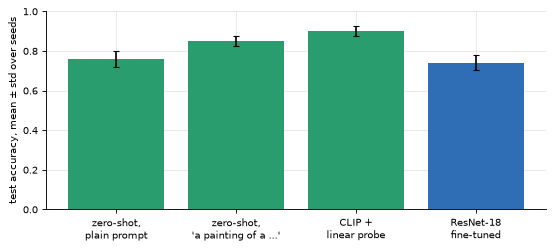

10 seeds. Seeds where CLIP beats the fine-tuned ResNet: zero shot simple 6, zero shot painting 10, linear probe 10
Cost: the image half of CLIP has 87.8 M parameters (351 MB); the full checkpoint 605 MB.


In [ ]:
clip = R("clip_classifier")
acc = clip["summary"]["test_acc"]
order = [("zero_shot_simple", "zero-shot,\nplain prompt", "clip"), ("zero_shot_painting", "zero-shot,\n'a painting of a ...'", "clip"),
         ("linear_probe", "CLIP +\nlinear probe", "clip"), ("resnet18_layer4", "ResNet-18\nfine-tuned", "resnet")]
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.bar([o[1] for o in order], [acc[o[0]]["mean"] for o in order], yerr=[acc[o[0]]["std"] for o in order], color=[COLORS[o[2]] for o in order], capsize=3)
ax.set_ylim(0, 1)
ax.set_ylabel("test accuracy, mean ± std over seeds")
plt.tight_layout()
plt.show()

wins = clip["summary"]["seeds_where_clip_beats_resnet"]
print(f"{clip['n_seeds']} seeds. Seeds where CLIP beats the fine-tuned ResNet: " + ", ".join(f"{k.replace('_', ' ')} {v}" for k, v in wins.items()))
c = clip["cost"]
print(f"Cost: the image half of CLIP has {c['params_image_tower'] / 1e6:.1f} M parameters ({c['fp32_mb_image_tower']:.0f} MB); the full checkpoint {c['fp32_mb_full_checkpoint']:.0f} MB.")

## 7. Style is harder than genre

The brief says "style or genre". Style (Impressionism, Realism, Symbolism...) is a historical category tied to the painter and to neighbouring movements, so it is much harder to
recognise in a painter the model has never seen. The same models are run on a six-style task, with the same artist-disjoint split, next to the metadata-only floors.

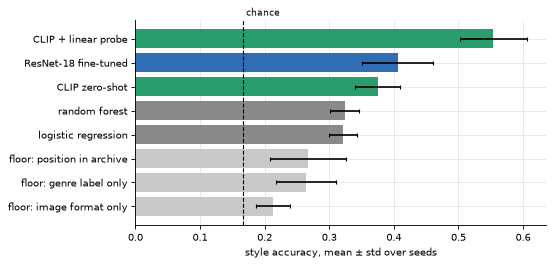

6 styles (Expressionism, Impressionism, Post-Impressionism, Realism, Romanticism, Symbolism), 1800 images, 50% by Unknown Artist, 10 seeds.
On paintings by named painters never seen in training: ResNet-18 36.1%; CLIP + probe 50.5%


In [ ]:
style = R("style_task")
acc = style["test_accuracy"]
rows = [("logistic_regression", "logistic regression", "classical"), ("random_forest", "random forest", "classical"), ("resnet18_layer4", "ResNet-18 fine-tuned", "resnet"),
        ("clip_zero_shot_style_of", "CLIP zero-shot", "clip"), ("clip_probe", "CLIP + linear probe", "clip"),
        ("floor_genre", "floor: genre label only", "floor"), ("floor_format", "floor: image format only", "floor"), ("floor_shard", "floor: position in archive", "floor")]
rows.sort(key=lambda r: acc[r[0]]["mean"])
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.barh([r[1] for r in rows], [acc[r[0]]["mean"] for r in rows], xerr=[acc[r[0]]["std"] for r in rows], color=[COLORS[r[2]] for r in rows], capsize=2)
ax.axvline(style["chance"], color="black", ls="--", lw=1)
ax.text(style["chance"], 1.01, " chance", transform=ax.get_xaxis_transform(), fontsize=8, va="bottom")
ax.set_xlabel("style accuracy, mean ± std over seeds")
plt.tight_layout()
plt.show()

comp = style["composition"]
print(f"{len(comp['classes'])} styles ({', '.join(c.replace('_', '-') for c in comp['classes'])}), {comp['n_images']} images, {pct(comp['unknown_artist_share'], 0)} by Unknown Artist, {style['n_seeds']} seeds.")
named = style["accuracy_by_artist_known"]
print("On paintings by named painters never seen in training: " + "; ".join(f"{label} {pct(named[key]['named_artist'])}" for key, label in (("resnet18_layer4", "ResNet-18"), ("clip_probe", "CLIP + probe"))))

## 8. Is another encoder worth it?

Bigger or newer frozen encoders were compared with CLIP ViT-B/32 on the same splits, accuracy against cost. The question is whether any is clearly better at a similar cost.

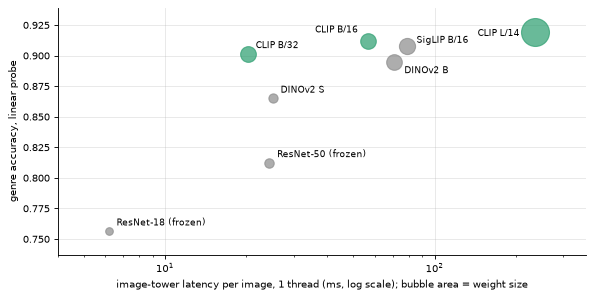

CLIP B/16 against CLIP B/32: +1.0 points on average, better on 7 of 10 seeds; 2.8x the latency, 345 MB.
CLIP L/14 against CLIP B/32: +1.8 points on average, better on 7 of 10 seeds; 11.6x the latency, 1216 MB.


In [ ]:
enc = R("encoder_comparison")
acc, cost = enc["accuracy"]["genre"], enc["cost"]
names = {"clip_b32": "CLIP B/32", "clip_b16": "CLIP B/16", "clip_l14": "CLIP L/14", "siglip_b16": "SigLIP B/16", "dinov2_s": "DINOv2 S", "dinov2_b": "DINOv2 B",
         "resnet50_frozen": "ResNet-50 (frozen)", "resnet18_frozen": "ResNet-18 (frozen)"}
OFFSETS = {"clip_l14": (-14, -4), "siglip_b16": (9, 3), "clip_b16": (-9, 8), "dinov2_b": (9, -10)}
fig, ax = plt.subplots(figsize=(7.5, 3.8))
for k, label in names.items():
    x, y, size = cost[k]["latency_ms"]["median_of_runs"], acc[k]["probe_acc"]["mean"], cost[k]["weights_mb"]
    ax.scatter(x, y, s=size / 2 + 25, color=COLORS["clip"] if k.startswith("clip") else COLORS["classical"], alpha=0.7, zorder=3)
    ax.annotate(label, (x, y), textcoords="offset points", xytext=OFFSETS.get(k, (7, 5)), fontsize=8, ha="right" if k in OFFSETS and OFFSETS[k][0] < 0 else "left")
ax.set_xscale("log")
ax.margins(x=0.12, y=0.12)
ax.set_xlabel("image-tower latency per image, 1 thread (ms, log scale); bubble area = weight size")
ax.set_ylabel("genre accuracy, linear probe")
plt.tight_layout()
plt.show()

for k in ("clip_b16", "clip_l14"):
    v = acc[k]["vs_clip_b32"]
    print(f"{names[k]} against CLIP B/32: {100 * v['mean_difference']:+.1f} points on average, better on {v['wins']} of {v['wins'] + v['ties'] + v['losses']} seeds; "
          f"{cost[k]['latency_ms']['median_of_runs'] / cost['clip_b32']['latency_ms']['median_of_runs']:.1f}x the latency, {cost[k]['weights_mb']:.0f} MB.")

## 9. Knowing when it is not sure

A kiosk that is wrong with confidence is worse than one that says "not sure". Raw probabilities are not well calibrated. A single **temperature**, fitted on the validation set,
brings the confidence closer to the real accuracy, and a confidence threshold lets the kiosk decline the least certain photos. Left: reliability (on the diagonal means calibrated).
Right: the accuracy of the answers that are kept, as the kiosk answers fewer photos.

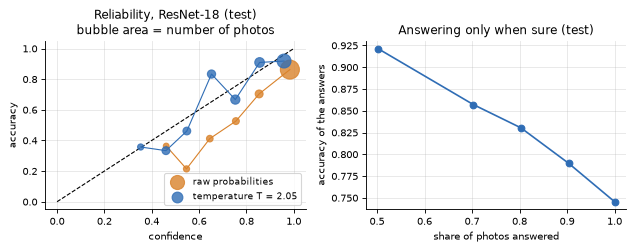

ResNet-18: expected calibration error 0.151 -> 0.077 with the temperature (mean confidence 88.8% for an accuracy of 74.6%).
CLIP head: expected calibration error 0.178 -> 0.033 (temperature 0.44, so it was under-confident, the opposite of the ResNet); 'unsure' below a probability of 0.83.


In [ ]:
cal = R("calibration")


def points(bins, min_photos=5):
    """(confidence, accuracy, number of photos) of the bins that hold at least `min_photos` photos."""
    pts = [p for p in bins if p["n"] >= min_photos]
    return [p["confidence"] for p in pts], [p["accuracy"] for p in pts], [p["n"] for p in pts]


fig, (a, b) = plt.subplots(1, 2, figsize=(8, 3.2))
a.plot([0, 1], [0, 1], "k--", lw=1)
for key, color, label in (("reliability_test_before", COLORS["mlp"], "raw probabilities"), ("reliability_test_after", COLORS["resnet"], f"temperature T = {cal['temperature']:.2f}")):
    cx, cy, n = points(cal[key])
    a.plot(cx, cy, "-", color=color, lw=1)
    a.scatter(cx, cy, s=np.array(n) * 1.5 + 10, color=color, alpha=0.8, label=label, zorder=3)
a.set_xlabel("confidence")
a.set_ylabel("accuracy")
a.set_title("Reliability, ResNet-18 (test)\nbubble area = number of photos")
a.legend(loc="lower right", fontsize=8)
rc = cal["test_risk_coverage"]
b.plot([r["realised_coverage"] for r in rc], [r["accuracy"] for r in rc], "o-", color=COLORS["resnet"])
b.set_xlabel("share of photos answered")
b.set_ylabel("accuracy of the answers")
b.set_title("Answering only when sure (test)")
plt.tight_layout()
plt.show()

probe = R("clip_probe")
print(f"ResNet-18: expected calibration error {cal['test_before']['ece']:.3f} -> {cal['test_after']['ece']:.3f} with the temperature (mean confidence {pct(cal['test_before']['mean_confidence'])} for an accuracy of {pct(cal['test_before']['accuracy'])}).")
print(f"CLIP head: expected calibration error {probe['test_before']['ece']:.3f} -> {probe['test_after']['ece']:.3f} (temperature {probe['temperature']:.2f}, so it was under-confident, the opposite of the ResNet); "
      f"'unsure' below a probability of {probe['min_confidence']:.2f}.")

## 10. A camera is not a clean test image

The test images are clean. A visitor's photo is rotated, blurred, seen at an angle or poorly lit. No real camera photos are used in this project, so the test uses
**proxies**: deterministic perturbations of the test images, and a ResNet trained with photo-style augmentation to see whether that helps.

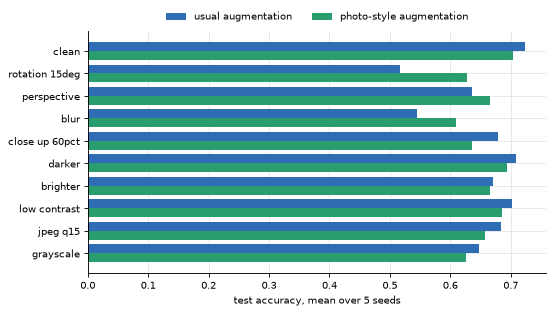

Photo-style augmentation minus usual augmentation (mean, points): clean -1.8; rotation 15deg +11.0; blur +6.4; close up 60pct -4.4


In [ ]:
ph = R("photo_robustness")
acc = ph["accuracy"]
keys = list(acc["standard"])
y = np.arange(len(keys))
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(y - 0.2, [acc["standard"][k]["mean"] for k in keys], height=0.4, color=COLORS["resnet"], label="usual augmentation")
ax.barh(y + 0.2, [acc["photo"][k]["mean"] for k in keys], height=0.4, color=COLORS["clip"], label="photo-style augmentation")
ax.set_yticks(y, [k.replace("_", " ") for k in keys])
ax.invert_yaxis()
ax.set_xlabel(f"test accuracy, mean over {ph['n_seeds']} seeds")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2, frameon=False)
plt.tight_layout()
plt.show()

d = ph["photo_minus_standard"]
print("Photo-style augmentation minus usual augmentation (mean, points): " + "; ".join(f"{k.replace('_', ' ')} {100 * d[k]['mean_diff']:+.1f}" for k in ("clean", "rotation_15deg", "blur", "close_up_60pct")))

## 11. What if it is not a painting?

Visitors will point the phone at a wall, a person or an object. A classifier that only knows five genres still answers, often with confidence. Left alone, the guide answers a share of these photos;
a separate "is this a painting?" check, built from CLIP and the collection, refuses almost all of them. The chart shows, per kind of non-painting, the share still **answered** at the
documented "unsure" thresholds (no refusal rule): lower is better, except for the paintings.

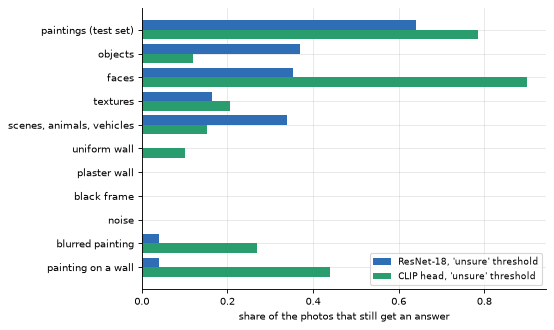

Chosen refusal rule: combination:museum_vs_everyday+similarity_top5; threshold fitted on validation images only (validation AUROC 0.991).
On the test set it accepts 97.8% of the paintings and 3.3% of the real non-painting photos; 82% of paintings photographed on a wall (a proxy for a framed painting).


In [ ]:
npj = R("non_painting")
ans = npj["answered_at_documented_thresholds"]
groups = [("paintings", "paintings (test set)"), ("caltech_objects", "objects"), ("caltech_faces", "faces"), ("dtd", "textures"), ("imagenette", "scenes, animals, vehicles"),
          ("uniform_wall", "uniform wall"), ("plaster_wall", "plaster wall"), ("black_frame", "black frame"), ("gaussian_noise", "noise"),
          ("blurred_painting", "blurred painting"), ("painting_on_wall", "painting on a wall")]
y = np.arange(len(groups))
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.barh(y - 0.2, [ans["resnet"][k] for k, _ in groups], height=0.4, color=COLORS["resnet"], label="ResNet-18, 'unsure' threshold")
ax.barh(y + 0.2, [ans["clip_head"][k] for k, _ in groups], height=0.4, color=COLORS["clip"], label="CLIP head, 'unsure' threshold")
ax.set_yticks(y, [label for _, label in groups])
ax.invert_yaxis()
ax.set_xlabel("share of the photos that still get an answer")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

rule = npj["chosen_rule"]["method"]
m = npj["methods"][rule]
print(f"Chosen refusal rule: {rule}; threshold fitted on validation images only (validation AUROC {m['validation_auroc_all_non_paintings']:.3f}).")
print(f"On the test set it accepts {pct(m['test_tpr_at_validation_threshold'])} of the paintings and {pct(m['all_real_photos']['accepted_at_validation_threshold'])} of the real non-painting photos; "
      f"{pct(m['test_accepted_painting_on_wall'], 0)} of paintings photographed on a wall (a proxy for a framed painting).")

## 12. What it costs on the kiosk

Kiosks run on modest CPUs. Each model was served from a fresh process, so the memory figure is that of loading and serving the model. The numbers are specific to the machine used
(printed below): trust the ratios between models more than the milliseconds. int8 and fp16 shrink CLIP's file but were **not** faster on this CPU.

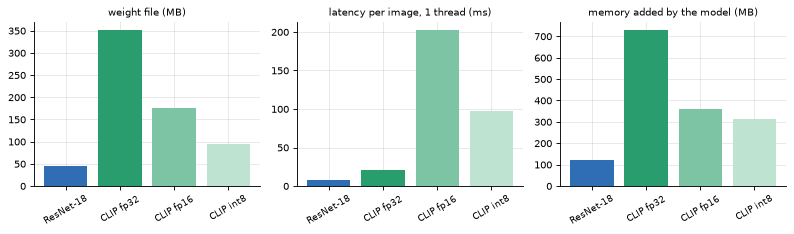

Machine: Apple M4, 10 cores, PyTorch 2.15.0. Latency includes reading the JPEG, resizing and the forward pass.


In [ ]:
kb = R("kiosk_benchmark")
cfg = {k: v["threads_1"] for k, v in kb["configs"].items()}
names = {"resnet18_fp32": "ResNet-18", "clip_fp32": "CLIP fp32", "clip_fp16": "CLIP fp16", "clip_int8": "CLIP int8"}
cols = [COLORS["resnet"], COLORS["clip"], "#7cc4a3", "#bfe3d1"]
panels = [("weight file (MB)", lambda c: c["weights_mb"]), ("latency per image, 1 thread (ms)", lambda c: c["total_ms"]["median_of_runs"]),
          ("memory added by the model (MB)", lambda c: c["rss_added_by_model_mb"])]
fig, axes = plt.subplots(1, 3, figsize=(10, 3))
for ax, (title, get) in zip(axes, panels):
    ax.bar(list(names.values()), [get(cfg[k]) for k in names], color=cols)
    ax.set_title(title, fontsize=9)
    ax.tick_params(axis="x", labelrotation=30, labelsize=8)
plt.tight_layout()
plt.show()
hw = kb["hardware"]
print(f"Machine: {hw.get('chip', hw['machine'])}, {hw['cpu_count']} cores, PyTorch {hw['torch']}. Latency includes reading the JPEG, resizing and the forward pass.")

## 13. Answering questions

The second job is search: type a question, get the best-matching paintings. The same CLIP model encodes the question and the paintings, and the collection's vectors are computed once.
Quality is measured on questions whose relevant paintings are defined by WikiArt metadata (genre, style and genre, artist), next to the level expected by chance. A French version of the
questions measures what is lost because CLIP is trained mostly on English.

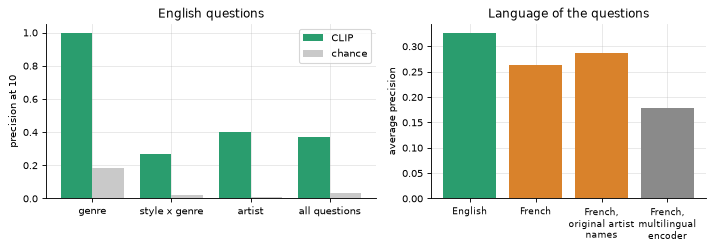

66 questions over a collection of 1500 paintings.
French questions with CLIP: average precision 0.327 -> 0.263.


In [ ]:
se = R("search_eval")["summary"]["bare"]
fr = R("search_french")["summary"]
types = [("genre", "genre"), ("style_genre", "style x genre"), ("artist", "artist"), ("all", "all questions")]
fig, (a, b) = plt.subplots(1, 2, figsize=(9, 3.2), gridspec_kw={"width_ratios": [1.2, 1]})
x = np.arange(len(types))
a.bar(x - 0.2, [se[t]["precision@10"] for t, _ in types], 0.4, color=COLORS["clip"], label="CLIP")
a.bar(x + 0.2, [se[t]["chance"]["precision@10"] for t, _ in types], 0.4, color=COLORS["floor"], label="chance")
a.set_xticks(x, [label for _, label in types])
a.set_ylabel("precision at 10")
a.set_title("English questions")
a.legend()
conds = [("clip_en", "English"), ("clip_fr", "French"), ("clip_fr_original_names", "French,\noriginal artist\nnames"), ("multilingual_fr", "French,\nmultilingual\nencoder")]
vals = [fr[c]["all"]["average_precision"] for c, _ in conds]
b.bar([label for _, label in conds], vals, color=[COLORS["clip"], COLORS["mlp"], COLORS["mlp"], COLORS["classical"]])
b.set_ylabel("average precision")
b.set_title("Language of the questions")
b.tick_params(axis="x", labelsize=8)
plt.tight_layout()
plt.show()

print(f"{R('search_eval')['n_queries']} questions over a collection of {R('search_eval')['collection_size']} paintings.")
print(f"French questions with CLIP: average precision {fr['clip_en']['all']['average_precision']:.3f} -> {fr['clip_fr']['all']['average_precision']:.3f}.")

## 14. The recommendation

Is a neural network worth it? **Yes, provided it is a pretrained one.** From scratch, a network is worse than the classical baseline; pretrained, it leads clearly.
The table gathers the key comparison. CLIP's image encoder with a linear head is the proposed model (it also serves the search, so the kiosk loads one model), with the fine-tuned ResNet-18
as the fallback when the CPU or memory is very constrained. The README's recommendation section gives the full reasoning and what is still open (real camera photos, new painters, the real kiosk CPU).

In [ ]:
rob_acc = R("robustness")["summary"]["test_acc"]
clip_acc = R("clip_classifier")["summary"]["test_acc"]
style_acc = R("style_task")["test_accuracy"]
base = R("baseline_classical")
mlp_final = R("mlp")["final"]
kiosk = R("kiosk_benchmark")["configs"]


def kiosk_row(key):
    c = kiosk[key]["threads_1"]
    return f"{c['weights_mb']:.0f}", f"{c['total_ms']['median_of_runs']:.1f}"


rows = {
    "Logistic regression": (mean_std(rob_acc["logistic_regression"]), mean_std(style_acc["logistic_regression"]), "-", f"{base['logistic_regression']['cpu_latency_ms']:.1f} *"),
    "Random forest": (mean_std(rob_acc["random_forest"]), mean_std(style_acc["random_forest"]), "-", f"{base['random_forest']['cpu_latency_ms']:.1f} *"),
    "Feed-forward network": (mean_std(rob_acc["mlp"]), "not run", "-", f"{mlp_final['cpu_latency_ms']:.1f} *"),
    "ResNet-18, fine-tuned": (mean_std(rob_acc["resnet18_layer4"]), mean_std(style_acc["resnet18_layer4"]), *kiosk_row("resnet18_fp32")),
    "CLIP image encoder + linear head": (mean_std(clip_acc["linear_probe"]), mean_std(style_acc["clip_probe"]), *kiosk_row("clip_fp32")),
}
table = pd.DataFrame(rows, index=["Genre accuracy", "Style accuracy", "Weights (MB)", "Latency (ms)"]).T
print("Accuracy: test accuracy, mean ± std over seeds. * latency from the first experiments, measured on another machine: compare orders of magnitude only.")
table

Accuracy: test accuracy, mean ± std over seeds. * latency from the first experiments, measured on another machine: compare orders of magnitude only.


,Genre accuracy,Style accuracy,Weights (MB),Latency (ms)
Logistic regression,49.0% ± 3.7,32.1% ± 2.2,-,1.5 *
Random forest,53.9% ± 5.2,32.4% ± 2.2,-,12.0 *
Feed-forward network,40.9% ± 6.0,not run,-,0.5 *
"ResNet-18, fine-tuned",74.0% ± 3.8,40.6% ± 5.4,45,7.2
CLIP image encoder + linear head,90.2% ± 2.5,55.4% ± 5.2,351,20.9


## Optional: run the guide on a photo

Everything above reads committed results. The cells below actually run the models, so they need the dataset in `data/`, the CLIP weights (downloaded on first use)
and a few minutes: they are **off by default**. Set `RUN_MODELS = True` to try them. They print text only; nothing here displays a painting.

In [ ]:
RUN_MODELS = False  # set to True to run the guide (needs data/wikiart_genre5 and the CLIP weights)

if RUN_MODELS:
    import subprocess
    import sys

    photo = next((ROOT / "data" / "wikiart_genre5" / "portrait").glob("*.jpg"))
    for cmd in (["scripts/predict.py", str(photo), "--model", "clip", "--story"],
                ["scripts/guide.py", str(photo), "--ask", "a snowy winter village", "--lang", "en"]):
        result = subprocess.run([sys.executable, *cmd], cwd=ROOT, capture_output=True, text=True)
        print("$ python", " ".join(cmd[:1]), "...")
        print(result.stdout or result.stderr)
else:
    print("Skipped: set RUN_MODELS = True to run the guide on a photo of the dataset.")

Skipped: set RUN_MODELS = True to run the guide on a photo of the dataset.
